In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d wordsforthewise/lending-club

Dataset URL: https://www.kaggle.com/datasets/wordsforthewise/lending-club
License(s): CC0-1.0
100% 1.26G/1.26G [00:08<00:00, 169MB/s]



In [ ]:
!unzip -q lending-club.zip -d lending_club

In [ ]:
import os

for root, dirs, files_list in os.walk('/content/lending_club'):
    for file in files_list:
        print(os.path.join(root, file))

/content/lending_club/accepted_2007_to_2018Q4.csv.gz
/content/lending_club/rejected_2007_to_2018Q4.csv.gz
/content/lending_club/rejected_2007_to_2018q4.csv/rejected_2007_to_2018Q4.csv
/content/lending_club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv


In [ ]:
!ls -lh /content/lending_club

total 619M
drwxr-xr-x 2 root root 4.0K Oct 25 16:28 accepted_2007_to_2018q4.csv
-rw-r--r-- 1 root root 375M Dec 17  2019 accepted_2007_to_2018Q4.csv.gz
drwxr-xr-x 2 root root 4.0K Oct 25 16:28 rejected_2007_to_2018q4.csv
-rw-r--r-- 1 root root 244M Dec 17  2019 rejected_2007_to_2018Q4.csv.gz


In [ ]:
import pandas as pd

df = pd.read_csv(
    '/content/lending_club/accepted_2007_to_2018Q4.csv.gz',
    low_memory=False
)

print(df.shape)
df.head()

(2260701, 151)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Columns: 151 entries, id to settlement_term
dtypes: float64(113), object(38)
memory usage: 2.5+ GB


In [ ]:

print(df['loan_status'].value_counts(dropna=False))

print("\nPercentages:")
print(df['loan_status'].value_counts(normalize=True, dropna=False) * 100)

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
NaN                                                         33
Name: count, dtype: int64

Percentages:
loan_status
Fully Paid                                             47.629076
Current                                                38.851533
Charged Off                                            11.879457
Late (31-120 days)                                      0.949573
In Grace Period                               

In [ ]:
date_cols = [col for col in df.columns if 'date' in col.lower() or 'issue' in col.lower()]

print(date_cols)

['issue_d', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'debt_settlement_flag_date', 'settlement_date']


In [ ]:
for col in date_cols:
    print(f"\n--- {col} ---")
    print(df[col].head())


--- issue_d ---
0    Dec-2015
1    Dec-2015
2    Dec-2015
3    Dec-2015
4    Dec-2015
Name: issue_d, dtype: object

--- hardship_start_date ---
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: hardship_start_date, dtype: object

--- hardship_end_date ---
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: hardship_end_date, dtype: object

--- payment_plan_start_date ---
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: payment_plan_start_date, dtype: object

--- debt_settlement_flag_date ---
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: debt_settlement_flag_date, dtype: object

--- settlement_date ---
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: settlement_date, dtype: object


In [ ]:
missing = df.isnull().mean().sort_values(ascending=False) * 100

missing_df = pd.DataFrame({
    'Missing_%': missing,
    'Missing_Count': df.isnull().sum()
})

missing_df.head(150)

,Missing_%,Missing_Count
acc_now_delinq,0.002743,62
acc_open_past_24mths,2.214490,50063
addr_state,0.001460,33
all_util,38.323555,866381
annual_inc,0.001637,37
...,...,...
total_rec_prncp,0.001460,33
total_rev_hi_lim,3.110053,70309
url,0.001460,33
verification_status,0.001460,33


In [ ]:
status_counts = (
    df['loan_status']
    .value_counts(dropna=False)
    .to_frame('Count')
)

status_counts['Percentage'] = (
    status_counts['Count'] / len(df) * 100
)

status_counts

,Count,Percentage
loan_status,,
Fully Paid,1076751,47.629076
Current,878317,38.851533
Charged Off,268559,11.879457
Late (31-120 days),21467,0.949573
In Grace Period,8436,0.373159
Late (16-30 days),4349,0.192374
Does not meet the credit policy. Status:Fully Paid,1988,0.087937
Does not meet the credit policy. Status:Charged Off,761,0.033662
Default,40,0.001769


In [ ]:
import pandas as pd
import numpy as np

print("Dataset shape:", df.shape)

print("\nLoan status counts:")
print(df["loan_status"].value_counts(dropna=False))

print("\nLoan status percentages:")
print(
    (df["loan_status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Dataset shape: (2260701, 151)

Loan status counts:
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
NaN                                                         33
Name: count, dtype: int64

Loan status percentages:
loan_status
Fully Paid                                             47.63
Current                                                38.85
Charged Off                                            11.88
Late (31-120 days)                                      0.95

In [ ]:
print("Issue date examples:")
print(df["issue_d"].head(10))

issue_dates = pd.to_datetime(
    df["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

print("\nEarliest issue date:", issue_dates.min())
print("Latest issue date:", issue_dates.max())
print("Unparsed issue dates:", issue_dates.isna().sum())

Issue date examples:
0    Dec-2015
1    Dec-2015
2    Dec-2015
3    Dec-2015
4    Dec-2015
5    Dec-2015
6    Dec-2015
7    Dec-2015
8    Dec-2015
9    Dec-2015
Name: issue_d, dtype: object

Earliest issue date: 2007-06-01 00:00:00
Latest issue date: 2018-12-01 00:00:00
Unparsed issue dates: 33


In [ ]:
post_origination_candidates = [
    "out_prncp",
    "out_prncp_inv",
    "total_pymnt",
    "total_pymnt_inv",
    "total_rec_prncp",
    "total_rec_int",
    "total_rec_late_fee",
    "recoveries",
    "collection_recovery_fee",
    "last_pymnt_d",
    "last_pymnt_amnt",
    "next_pymnt_d",
    "last_credit_pull_d",
    "hardship_flag",
    "hardship_type",
    "hardship_reason",
    "hardship_status",
    "settlement_status",
    "settlement_date",
    "settlement_amount",
    "settlement_percentage",
    "debt_settlement_flag",
    "debt_settlement_flag_date"
]

print("Post-origination candidates present in dataset:")
print([c for c in post_origination_candidates if c in df.columns])

Post-origination candidates present in dataset:
['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 'settlement_status', 'settlement_date', 'settlement_amount', 'settlement_percentage', 'debt_settlement_flag', 'debt_settlement_flag_date']


In [ ]:
for i, col in enumerate(df.columns, start=1):
    print(i, col)

1 id
2 member_id
3 loan_amnt
4 funded_amnt
5 funded_amnt_inv
6 term
7 int_rate
8 installment
9 grade
10 sub_grade
11 emp_title
12 emp_length
13 home_ownership
14 annual_inc
15 verification_status
16 issue_d
17 loan_status
18 pymnt_plan
19 url
20 desc
21 purpose
22 title
23 zip_code
24 addr_state
25 dti
26 delinq_2yrs
27 earliest_cr_line
28 fico_range_low
29 fico_range_high
30 inq_last_6mths
31 mths_since_last_delinq
32 mths_since_last_record
33 open_acc
34 pub_rec
35 revol_bal
36 revol_util
37 total_acc
38 initial_list_status
39 out_prncp
40 out_prncp_inv
41 total_pymnt
42 total_pymnt_inv
43 total_rec_prncp
44 total_rec_int
45 total_rec_late_fee
46 recoveries
47 collection_recovery_fee
48 last_pymnt_d
49 last_pymnt_amnt
50 next_pymnt_d
51 last_credit_pull_d
52 last_fico_range_high
53 last_fico_range_low
54 collections_12_mths_ex_med
55 mths_since_last_major_derog
56 policy_code
57 application_type
58 annual_inc_joint
59 dti_joint
60 verification_status_joint
61 acc_now_delinq
62 tot_co

In [ ]:

import pandas as pd
import numpy as np

# Work with a copy of the dataset
data = df.copy()

# Parse issue dates
data["issue_d"] = pd.to_datetime(
    data["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

# Map final loan outcomes
target_mapping = {
    "Fully Paid": 0,
    "Does not meet the credit policy. Status:Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1,
    "Does not meet the credit policy. Status:Charged Off": 1
}

data["default"] = data["loan_status"].map(target_mapping)

# Keep only loans with a known final outcome and valid issue date
data = data.dropna(subset=["default", "issue_d"]).copy()
data["default"] = data["default"].astype(int)

# Show the resulting dataset
print("Eligible loans:", len(data))
print("\nTarget distribution:")
print(data["default"].value_counts())
print("\nTarget percentages:")
print((data["default"].value_counts(normalize=True) * 100).round(2))

print("\nIssue date range:")
print("Earliest:", data["issue_d"].min())
print("Latest:", data["issue_d"].max())

print("\nYearly loan counts:")
print(data["issue_d"].dt.year.value_counts().sort_index())


Eligible loans: 1348099

Target distribution:
default
0    1078739
1     269360
Name: count, dtype: int64

Target percentages:
default
0    80.02
1    19.98
Name: proportion, dtype: float64

Issue date range:
Earliest: 2007-06-01 00:00:00
Latest: 2018-12-01 00:00:00

Yearly loan counts:
issue_d
2007       603
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134804
2014    223103
2015    375546
2016    293105
2017    169321
2018     56318
Name: count, dtype: int64


In [ ]:

# Chronological split based on loan issue date
train_df = data[data["issue_d"] < "2016-01-01"].copy()

valid_df = data[
    (data["issue_d"] >= "2016-01-01") &
    (data["issue_d"] < "2017-01-01")
].copy()

test_df = data[data["issue_d"] >= "2017-01-01"].copy()

def summarize_period(name, frame):
    print(f"\n{name}")
    print("Loans:", len(frame))
    print("Defaults:", int(frame["default"].sum()))
    print("Default rate (%):", round(frame["default"].mean() * 100, 2))

summarize_period("TRAIN: 2007–2015", train_df)
summarize_period("VALIDATION: 2016", valid_df)
summarize_period("TEST: 2017–2018", test_df)



TRAIN: 2007–2015
Loans: 829355
Defaults: 153065
Default rate (%): 18.46

VALIDATION: 2016
Loans: 293105
Defaults: 68252
Default rate (%): 23.29

TEST: 2017–2018
Loans: 225639
Defaults: 48043
Default rate (%): 21.29


In [ ]:

# Candidate predictors available around loan origination
candidate_features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "earliest_cr_line",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "mths_since_last_delinq",
    "mths_since_last_record",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "initial_list_status",
    "application_type",
    "acc_now_delinq",
    "tot_coll_amt",
    "tot_cur_bal",
    "total_rev_hi_lim",
    "collections_12_mths_ex_med",
    "annual_inc_joint",
    "dti_joint",
    "verification_status_joint",
    "disbursement_method"
]

# Keep only columns present in the dataset
features = [col for col in candidate_features if col in data.columns]

print("Candidate features found:", len(features))
print(features)

# Missing-value percentage in the training data only
missing_pct = (
    train_df[features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("\nMissing values in training data (%):")
print(missing_pct.round(2))

# Remove predictors with more than 50% missing values in training data
features_kept = missing_pct[missing_pct <= 50].index.tolist()
features_removed = missing_pct[missing_pct > 50].index.tolist()

print("\nFeatures retained:", len(features_kept))
print(features_kept)

print("\nFeatures removed due to >50% missingness:", len(features_removed))
print(features_removed)


Candidate features found: 35
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'collections_12_mths_ex_med', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'disbursement_method']

Missing values in training data (%):
dti_joint                     99.95
annual_inc_joint              99.95
verification_status_joint     99.95
mths_since_last_record        84.38
mths_since_last_delinq        51.30
tot_cur_bal                    8.47
tot_coll_amt                   8.47
total_rev_hi_lim               8.47
emp_length                     5.14
revol_util         

In [ ]:

from sklearn.model_selection import train_test_split

SAMPLE_SIZE = 60_000
RANDOM_STATE = 42

# Allocate the sample proportionally to each period's size
total_rows = len(train_df) + len(valid_df) + len(test_df)

n_train = round(SAMPLE_SIZE * len(train_df) / total_rows)
n_valid = round(SAMPLE_SIZE * len(valid_df) / total_rows)
n_test = SAMPLE_SIZE - n_train - n_valid

def stratified_sample(frame, n, seed=42):
    if n > len(frame):
        raise ValueError("Sample size exceeds the number of available rows.")

    sampled, _ = train_test_split(
        frame,
        train_size=n,
        random_state=seed,
        stratify=frame["default"]
    )
    return sampled.copy()

train_sample = stratified_sample(train_df, n_train, RANDOM_STATE)
valid_sample = stratified_sample(valid_df, n_valid, RANDOM_STATE + 1)
test_sample = stratified_sample(test_df, n_test, RANDOM_STATE + 2)

print("Sample sizes:")
print("Train:", len(train_sample))
print("Validation:", len(valid_sample))
print("Test:", len(test_sample))
print("Total:", len(train_sample) + len(valid_sample) + len(test_sample))

for name, sample in [
    ("Train", train_sample),
    ("Validation", valid_sample),
    ("Test", test_sample)
]:
    print(f"\n{name} default rate: {sample['default'].mean() * 100:.2f}%")


Sample sizes:
Train: 36912
Validation: 13045
Test: 10043
Total: 60000

Train default rate: 18.45%

Validation default rate: 23.29%

Test default rate: 21.29%


In [ ]:

# Start from features selected using training-period missingness
model_features = [
    col for col in features_kept
    if col != "grade"
]

def make_model_frame(frame, columns):
    X = frame[columns].copy()
    y = frame["default"].copy()

    # Convert credit history date to approximate age in years
    if "earliest_cr_line" in X.columns:
        credit_date = pd.to_datetime(
            X["earliest_cr_line"],
            format="%b-%Y",
            errors="coerce"
        )

        issue_date = frame["issue_d"]
        X["credit_history_years"] = (
            (issue_date - credit_date).dt.days / 365.25
        )

        X = X.drop(columns=["earliest_cr_line"])

    # Treat remaining object/string features as categorical
    categorical_cols = X.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    numerical_cols = [
        col for col in X.columns
        if col not in categorical_cols
    ]

    # Convert numeric columns to numeric types where possible
    for col in numerical_cols:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    return X, y, categorical_cols

X_train, y_train, cat_cols = make_model_frame(
    train_sample, model_features
)
X_valid, y_valid, _ = make_model_frame(
    valid_sample, model_features
)
X_test, y_test, _ = make_model_frame(
    test_sample, model_features
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)
print("Test shape:", X_test.shape)
print("\nCategorical columns:", cat_cols)
print("\nTarget counts in training:")
print(y_train.value_counts())


Training shape: (36912, 29)
Validation shape: (13045, 29)
Test shape: (10043, 29)

Categorical columns: ['emp_length', 'term', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'application_type', 'initial_list_status', 'disbursement_method']

Target counts in training:
default
0    30100
1     6812
Name: count, dtype: int64


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

numeric_cols = [
    col for col in X_train.columns
    if col not in cat_cols
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, cat_cols)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=50,
        class_weight=None,
        random_state=RANDOM_STATE
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    valid_prob = pipeline.predict_proba(X_valid)[:, 1]
    valid_pred = (valid_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, valid_pred),
        "Precision": precision_score(
            y_valid, valid_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, valid_pred, zero_division=0
        ),
        "F1": f1_score(
            y_valid, valid_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_valid, valid_prob)
    })

    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression    0.7730     0.7127  0.0425 0.0801   0.7144
      Decision Tree    0.7651     0.4831  0.1224 0.1954   0.6614


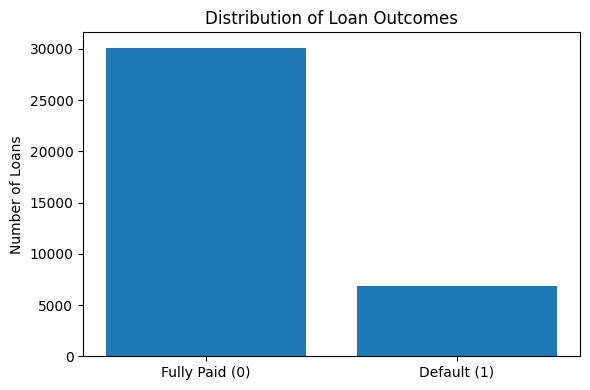

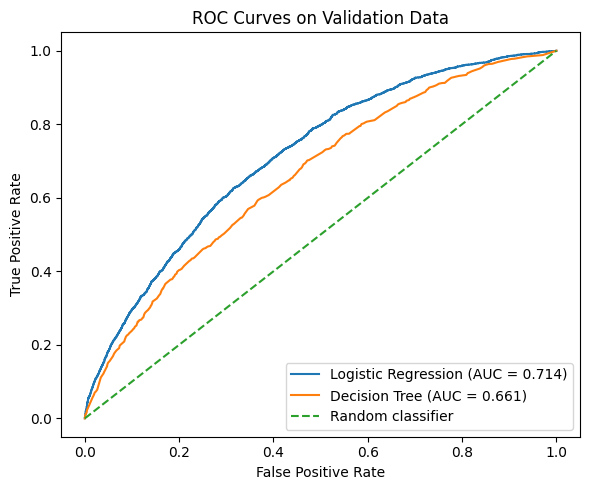

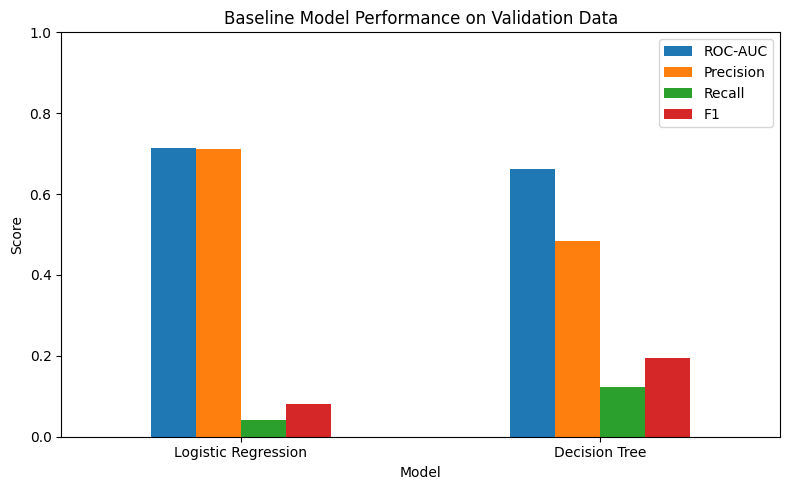

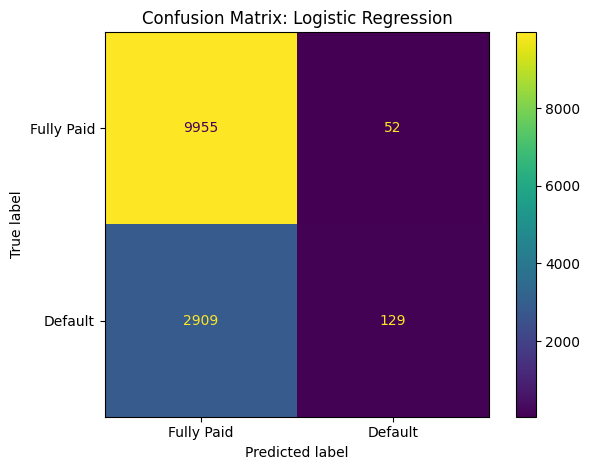

Figures saved as PNG files at 300 DPI.


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Figure 1: Distribution of loan outcomes
plt.figure(figsize=(6, 4))
counts = train_sample["default"].value_counts().sort_index()
plt.bar(["Fully Paid (0)", "Default (1)"], counts.values)
plt.title("Distribution of Loan Outcomes")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.savefig("figure1_loan_distribution.png", dpi=300)
plt.show()


# Figure 2: ROC curves for baseline models
plt.figure(figsize=(6, 5))

for name, pipeline in fitted_models.items():
    probabilities = pipeline.predict_proba(X_valid)[:, 1]
    fpr, tpr, _ = roc_curve(y_valid, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves on Validation Data")
plt.legend()
plt.tight_layout()
plt.savefig("figure2_roc_curves.png", dpi=300)
plt.show()


# Figure 3: Comparison of baseline model metrics
metric_columns = ["ROC-AUC", "Precision", "Recall", "F1"]
results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Baseline Model Performance on Validation Data")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figure3_model_comparison.png", dpi=300)
plt.show()


# Figure 4: Confusion matrix for the model with the highest ROC-AUC
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

valid_probabilities = best_model.predict_proba(X_valid)[:, 1]
valid_predictions = (valid_probabilities >= 0.5).astype(int)

cm = confusion_matrix(y_valid, valid_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fully Paid", "Default"]
)
display.plot(values_format="d")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.savefig("figure4_confusion_matrix.png", dpi=300)
plt.show()

print("Figures saved as PNG files at 300 DPI.")
